**Live Demo:** `PASTE YOUR STREAMLIT LINK HERE`
**GitHub Repo:** `PASTE YOUR GITHUB REPO LINK HERE`

In [1]:
# NumPy: arrays and math
import numpy as np
# Pandas: DataFrames and reading/writing data
import pandas as pd
# Pickle: saving and loading the trained model
import pickle
# train_test_split: divide data into training and testing sets
from sklearn.model_selection import train_test_split
# LabelEncoder: convert categorical values into numeric codes
from sklearn.preprocessing import LabelEncoder
# Support Vector Machine model
from sklearn import svm
# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# PrettyTable: display results in a clean table
from prettytable import PrettyTable
# Plotting (confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

cleveland_data = pd.read_csv("processed.cleveland.data", names=column_names, na_values="?")

print(cleveland_data.head())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  
Shape: (303, 14)


In [11]:
sex_map   = {0: "Female", 1: "Male"}
cp_map    = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-Anginal Pain", 4: "Asymptomatic"}
exang_map = {0: "No", 1: "Yes"}
slope_map = {1: "Upsloping", 2: "Flat", 3: "Downsloping"}

sample_data = pd.DataFrame({
    "Sex":            cleveland_data["sex"].map(sex_map),
    "ChestPain":      cleveland_data["cp"].map(cp_map),
    "ExerciseAngina": cleveland_data["exang"].map(exang_map),
    "SlopeST":        cleveland_data["slope"].map(slope_map),
    "HeartDisease":   cleveland_data["num"].apply(lambda v: "Yes" if v > 0 else "No"),
})


print("Sample Data:")

pd.set_option("display.max_rows", 20, "display.max_columns", None)
print(sample_data)

Sample Data:
        Sex         ChestPain ExerciseAngina      SlopeST HeartDisease
0      Male    Typical Angina             No  Downsloping           No
1      Male      Asymptomatic            Yes         Flat          Yes
2      Male      Asymptomatic            Yes         Flat          Yes
3      Male  Non-Anginal Pain             No  Downsloping           No
4    Female   Atypical Angina             No    Upsloping           No
..      ...               ...            ...          ...          ...
298    Male    Typical Angina             No         Flat          Yes
299    Male      Asymptomatic             No         Flat          Yes
300    Male      Asymptomatic            Yes         Flat          Yes
301  Female   Atypical Angina             No         Flat          Yes
302    Male  Non-Anginal Pain             No    Upsloping           No

[303 rows x 5 columns]


In [12]:
print("Attributes in Sample Data:")

print(sample_data.columns)

print("Number of Instances in Sample Data:", sample_data["Sex"].count())

print("Output distribution:")
print(sample_data["HeartDisease"].value_counts())

Attributes in Sample Data:
Index(['Sex', 'ChestPain', 'ExerciseAngina', 'SlopeST', 'HeartDisease'], dtype='str')
Number of Instances in Sample Data: 303
Output distribution:
HeartDisease
No     164
Yes    139
Name: count, dtype: int64


In [5]:
# The 4 selected attributes contain no missing values, so no pre-processing is needed.
print("Missing values per attribute:")
print(sample_data.isnull().sum())

Missing values per attribute:
Sex               0
ChestPain         0
ExerciseAngina    0
SlopeST           0
HeartDisease      0
dtype: int64


In [6]:
# Define all possible values of each attribute
sex = pd.DataFrame({"Sex": ["Female", "Male"]})
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
slope_st = pd.DataFrame({"SlopeST": ["Upsloping", "Flat", "Downsloping"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects
sex_label_encoder = LabelEncoder()
chest_pain_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
slope_st_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

# Train (fit) the encoders
sex_label_encoder.fit(np.ravel(sex))
chest_pain_label_encoder.fit(np.ravel(chest_pain))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
slope_st_label_encoder.fit(np.ravel(slope_st))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

# Show the numeric code given to each value
for name, enc in [("Sex", sex_label_encoder), ("ChestPain", chest_pain_label_encoder),
                  ("ExerciseAngina", exercise_angina_label_encoder), ("SlopeST", slope_st_label_encoder),
                  ("HeartDisease", heart_disease_label_encoder)]:
    print(name, "->", dict(zip(enc.classes_, enc.transform(enc.classes_))))

Sex -> {'Female': np.int64(0), 'Male': np.int64(1)}
ChestPain -> {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-Anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
ExerciseAngina -> {'No': np.int64(0), 'Yes': np.int64(1)}
SlopeST -> {'Downsloping': np.int64(0), 'Flat': np.int64(1), 'Upsloping': np.int64(2)}
HeartDisease -> {'No': np.int64(0), 'Yes': np.int64(1)}


In [28]:
sample_data_encoded_output = sample_data.copy()

print("HeartDisease Attribute After Label Encoding:")
sample_data["encoded_heart_disease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heart_disease"]].head(10))

sample_data_encoded_output[["Sex", "ChestPain", "ExerciseAngina", "SlopeST", "HeartDisease"]] = sample_data[["Sex", "ChestPain", "ExerciseAngina", "SlopeST", "encoded_heart_disease"]]


HeartDisease Attribute After Label Encoding:
  HeartDisease  encoded_heart_disease
0           No                      0
1          Yes                      1
2          Yes                      1
3           No                      0
4           No                      0
5           No                      0
6          Yes                      1
7           No                      0
8          Yes                      1
9          Yes                      1


In [57]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded_output["encoded_chest_pain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exercise_angina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_slope_st"] = slope_st_label_encoder.transform(sample_data_encoded_output["SlopeST"])

sample_data_encoded[["Sex", "ChestPain", "ExerciseAngina", "SlopeST", "HeartDisease"]] = sample_data_encoded_output[["encoded_sex", "encoded_chest_pain", "encoded_exercise_angina", "encoded_slope_st", "HeartDisease"]]

print("Sample Data after Label Encoding:")
print(sample_data_encoded.head(10))

Sample Data after Label Encoding:
   Sex  ChestPain  ExerciseAngina  SlopeST  HeartDisease  \
0    1          3               0        0             0   
1    1          0               1        1             1   
2    1          0               1        1             1   
3    1          2               0        0             0   
4    0          1               0        2             0   
5    1          1               0        2             0   
6    0          0               0        0             1   
7    0          0               1        2             0   
8    1          0               0        1             1   
9    1          0               1        0             1   

   encoded_heart_disease  encoded_sex  encoded_chest_pain  \
0                      0            1                   3   
1                      1            1                   0   
2                      1            1                   0   
3                      0            1                   2   


In [48]:
# 80% training, 20% testing; same settings as the Titanic notebook
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=42,
    shuffle=False
)


In [49]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 9)
Output labels (train) shape: (242,)


In [50]:
print("Training the Support Vector Classifier on Training Data")

svc_model = svm.SVC(gamma="auto", random_state=42)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)

Training the Support Vector Classifier on Training Data
SVC(gamma='auto', random_state=42)


In [51]:
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


In [52]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 9)
Output labels (test) shape: (61,)


In [53]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


In [54]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions


model_predictions = testing_data_encoded
print("Predictions Returned by heart_svc_trained_model:")

print(model_predictions)

Predictions Returned by heart_svc_trained_model:
     Sex  ChestPain  ExerciseAngina  SlopeST  HeartDisease  \
242    0          0               0        2             0   
243    1          3               0        1             1   
244    0          2               0        2             0   
245    1          0               0        1             1   
246    1          0               0        2             1   
..   ...        ...             ...      ...           ...   
298    1          3               0        1             1   
299    1          0               0        1             1   
300    1          0               1        1             1   
301    0          1               0        1             1   
302    1          2               0        2             0   

     encoded_heart_disease  encoded_sex  encoded_chest_pain  \
242                      0            0                   0   
243                      1            1                   3   
244              

In [55]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("Accuracy Score:")

print(round(model_accuracy_score, 2))

Accuracy Score:
0.34


Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.03      0.06        29
           1       0.62      0.62      0.62        32
           2       0.00      0.00      0.00         0

    accuracy                           0.34        61
   macro avg       0.32      0.22      0.23        61
weighted avg       0.49      0.34      0.36        61

Confusion Matrix:
           Predicted: 0  Predicted: 1  Predicted: 2
Actual: 0             1            12            16
Actual: 1             2            20            10
Actual: 2             0             0             0


c:\Users\itworld\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\itworld\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\itworld\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"

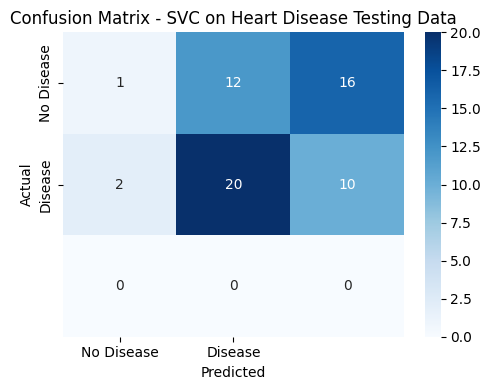

In [61]:
print("Classification Report:")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"]))
conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
labels = np.unique(
    np.concatenate([
        model_predictions["HeartDisease"].to_numpy(),
        model_predictions["Predictions"].to_numpy()
    ])
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)
print("Confusion Matrix:")

print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

In [62]:
# Demo patient (edit these values, or replace them with input() calls):
#   sex_input = input("Sex (Female, Male): ").strip()
#   chest_pain_input = input("Chest Pain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
#   exercise_angina_input = input("Exercise Angina (No, Yes): ").strip()
#   slope_st_input = input("Slope of ST segment (Upsloping, Flat, Downsloping): ").strip()
sex_input = "Male"
chest_pain_input = "Asymptomatic"
exercise_angina_input = "Yes"
slope_st_input = "Flat"

print(f"Sex: {sex_input}, ChestPain: {chest_pain_input}, ExerciseAngina: {exercise_angina_input}, SlopeST: {slope_st_input}")

Sex: Male, ChestPain: Asymptomatic, ExerciseAngina: Yes, SlopeST: Flat


In [64]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chest_pain_input],
    "ExerciseAngina": [exercise_angina_input],
    "SlopeST": [slope_st_input]
})

print("User Input Feature Vector:")
print(user_input)

User Input Feature Vector:
    Sex     ChestPain ExerciseAngina SlopeST
0  Male  Asymptomatic            Yes    Flat


In [65]:
unseen_data_features = user_input.copy()

unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])
unseen_data_features["SlopeST"] = slope_st_label_encoder.transform(user_input["SlopeST"])

print("User Input Encoded Feature Vector:")

print(unseen_data_features)

User Input Encoded Feature Vector:
   Sex  ChestPain  ExerciseAngina  SlopeST
0    1          0               1        1


#### Step 8.4: Load the Saved Model

In [66]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

In [ ]:
feature_columns = ["Sex", "ChestPain", "ExerciseAngina", "SlopeST"]

input_vector_train = training_data_encoded[feature_columns]
output_label_train = training_data_encoded["HeartDisease"]

svc_model = svm.SVC(gamma="auto", random_state=42)
svc_model.fit(input_vector_train, output_label_train)

model = svc_model

predicted_heart_disease = int(
    model.predict(unseen_data_features[feature_columns])[0]
)

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE"
else:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

if predicted_heart_disease == 1:
    prediction = "HEART DISEASE"
if predicted_heart_disease == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- HeartDisease
- encoded_chest_pain
- encoded_exercise_angina
- encoded_heart_disease
- encoded_sex
